# Identificação do projeto

**Título do projeto:** Perfil das faixas populares nos charts da Deezer por gênero  
**Integrantes do grupo:** Eduardo Fabri, João Correa, Rodrigo Alves e João Pedro Cardoso  
**Turma:** Bacharelado em Sistemas de Informação • 2º semestre de 2026  
**Descrição breve do problema ou contexto:** os charts da Deezer dizem quais faixas estão no topo de cada gênero, mas não o que elas têm em comum. Este notebook usa o conjunto preparado no RA1 para descrever e comparar, entre gêneros, a duração das faixas, a idade do lançamento, a popularidade do artista e a concentração de artistas no ranking, e testa uma previsão simples com Machine Learning.

---

# RA3 — Analysis, Visualization and Machine Learning

Utilize os dados preparados e processados nas etapas anteriores para produzir análises estatísticas, visualizações e interpretações que contribuam para responder ao problema definido. Explore também uma aplicação simples de Machine Learning, por classificação ou regressão, para investigar uma possibilidade de previsão a partir dos dados.

## 1. Análise estatística descritiva

Realize uma análise estatística dos dados, contemplando:

- **Tendência central:** utilização de média e/ou mediana para compreender valores representativos.
- **Dispersão:** utilização de medidas como amplitude ou desvio-padrão para analisar a variabilidade.
- **Distribuição:** investigação da frequência, concentração ou distribuição dos valores.

As medidas utilizadas devem ser coerentes com as características dos dados e com o problema investigado. Apresente os resultados e explique o que eles representam no contexto do projeto.

In [1]:
# Preparação do ambiente: bibliotecas, pastas do projeto e origem dos dados
import subprocess
import sys
from pathlib import Path

import pandas as pd

URL_REPOSITORIO = "https://github.com/Jcliz/machine-learning-ra3.git"
PASTA_CLONE = "machine-learning-ra3"
RAMO = "main"  # no Colab, troque pelo ramo do repositório que quiser executar
NO_COLAB = "google.colab" in sys.modules

if NO_COLAB:
    if Path(PASTA_CLONE).exists():
        # Clone de uma execução anterior nesta sessão do Colab: traz a versão mais nova do ramo
        subprocess.run(["git", "-C", PASTA_CLONE, "pull", "-q", "origin", RAMO], check=False)
    else:
        subprocess.run(["git", "clone", "-q", "-b", RAMO, URL_REPOSITORIO], check=True)

# O conjunto preparado fica em dados/ no repositório da entrega e em dados/preparados/ no de desenvolvimento
candidatos = [Path(PASTA_CLONE), Path.cwd(), Path.cwd().parent]
encontrados = [
    (p.resolve(), arquivo.resolve())
    for p in candidatos if (p / "requirements.txt").exists()
    for arquivo in (p / "dados" / "faixas_preparadas.csv", p / "dados" / "preparados" / "faixas_preparadas.csv")
    if arquivo.exists()
]
if not encontrados:
    raise FileNotFoundError(
        "Conjunto preparado não encontrado (dados/faixas_preparadas.csv ao lado do requirements.txt). "
        f"Rode o notebook de dentro do clone (raiz ou notebook/) ou, no Colab, confira o ramo '{RAMO}'."
    )
RAIZ, ARQUIVO_PREPARADO = encontrados[0]
PASTA_PREPARADOS = ARQUIVO_PREPARADO.parent

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
print(f"Raiz do projeto: {RAIZ.name}")  # só o nome da pasta: o caminho completo é da máquina de quem executa
print(f"Ambiente: {'Google Colab' if NO_COLAB else 'local'} · Python {sys.version.split()[0]} · pandas {pd.__version__}")

Raiz do projeto: data-analytics
Ambiente: local · Python 3.13.1 · pandas 2.3.3


In [2]:
# Releitura do conjunto preparado para a análise
colunas_inteiras_analise = ["id_faixa", "id_chart", "posicao_chart", "id_artista", "id_album",
                            "duracao_s", "rank", "numero_fas"]
colunas_texto_analise = ["titulo", "genero", "tipo_chart", "artista"]
colunas_booleanas_analise = ["lancamento_posterior_coleta", "duracao_fora_limites_iqr"]
df_analise = pd.read_csv(
    ARQUIVO_PREPARADO, encoding="utf-8",
    dtype={**{c: "int64" for c in colunas_inteiras_analise},
           **{c: "string" for c in colunas_texto_analise},
           **{c: "bool" for c in colunas_booleanas_analise}},
    parse_dates=["data_lancamento", "data_coleta"],
)
print(f"{len(df_analise)} ocorrências faixa-chart, {df_analise['id_faixa'].nunique()} faixas distintas, "
      f"{df_analise.loc[df_analise['tipo_chart'].eq('genero'), 'genero'].nunique()} charts de gênero "
      f"e {df_analise['tipo_chart'].eq('geral').sum()} ocorrências no chart geral.")

2800 ocorrências faixa-chart, 2581 faixas distintas, 27 charts de gênero e 100 ocorrências no chart geral.


In [3]:
# Utilize quantas células de código forem necessárias para esta etapa.

**Resposta do grupo:**

[Preencha aqui.]

## 2. Visualização e interpretação dos dados

Produza pelo menos três visualizações que contribuam para compreender diferentes características dos dados. As visualizações deverão:

- Ser adequadas às informações apresentadas.
- Possuir identificação clara das variáveis e dos resultados.
- Ser acompanhadas de uma breve interpretação.

Identifique padrões, tendências, diferenças ou comportamentos relevantes, evitando limitar a análise à simples apresentação de gráficos.

In [4]:
# Recorte e convenções das visualizações
from inspect import signature as assinatura

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

from IPython.display import display

# Cada gráfico usa somente o conjunto relido na seção 1, sem depender de outras medidas.
df_generos_vis = df_analise.loc[df_analise["tipo_chart"].eq("genero")].copy()
df_geral_vis = df_analise.loc[df_analise["tipo_chart"].eq("geral")].copy()
data_retrato_vis = df_analise["data_coleta"].min().strftime("%d/%m/%Y")
estilo_vis = {
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
}
print(f"Comparações por gênero: {len(df_generos_vis)} ocorrências faixa-chart, "
      f"{df_generos_vis['genero'].nunique()} charts. "
      f"Referência geral separada: {len(df_geral_vis)} ocorrências.")

Comparações por gênero: 2700 ocorrências faixa-chart, 27 charts. Referência geral separada: 100 ocorrências.


**Resposta do grupo:**

As comparações usam as 2.700 ocorrências dos charts de gênero; as 100 do chart geral são apresentadas separadamente na P3. Uma faixa presente em dois charts participa de ambos, pois o grupo de comparação é o chart de origem. Fonte: seção 2, célula "Recorte e convenções das visualizações".

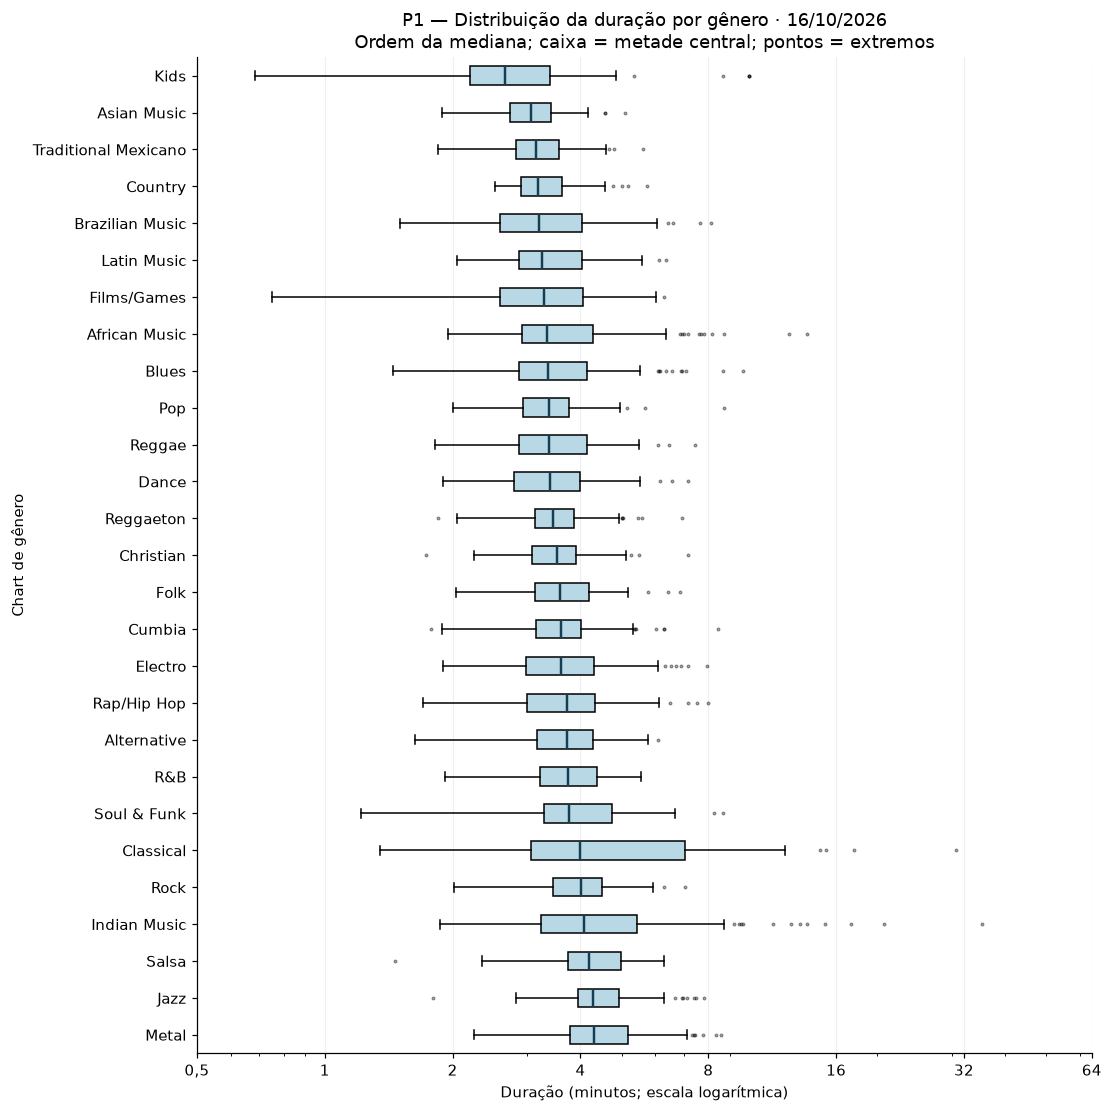

,ocorrencias,mediana_s,minimo_s,maximo_s
genero,,,,
Kids,100,159.5,41,599
Asian Music,100,184.0,113,305
Traditional Mexicano,100,188.5,111,336
Country,100,191.0,151,345
Brazilian Music,100,191.5,90,487
Latin Music,100,194.5,123,381
Films/Games,100,196.5,45,377
African Music,100,200.5,117,821
Blues,100,201.0,87,578


In [5]:
# Duração por gênero (boxplot)
resumo_duracao_vis = (
    df_generos_vis.groupby("genero")["duracao_s"]
    .agg(ocorrencias="size", mediana_s="median", minimo_s="min", maximo_s="max")
    .sort_values("mediana_s")
)
with plt.rc_context(estilo_vis):
    figura_vis, eixo_vis = plt.subplots(figsize=(10, 10), layout="constrained")
    duracoes_vis = [
        df_generos_vis.loc[df_generos_vis["genero"].eq(genero_vis), "duracao_s"] / 60
        for genero_vis in resumo_duracao_vis.index
    ]
    # Compatibilidade com matplotlib 3.8 e com a orientação nomeada das versões recentes.
    orientacao_vis = ({"orientation": "horizontal"} if "orientation" in assinatura(eixo_vis.boxplot).parameters
                      else {"vert": False})
    caixas_vis = eixo_vis.boxplot(
        duracoes_vis, **orientacao_vis, patch_artist=True,
        medianprops={"color": "#153e52", "linewidth": 1.6},
        flierprops={"marker": ".", "markersize": 3, "alpha": 0.5},
    )
    for caixa_vis in caixas_vis["boxes"]:
        caixa_vis.set_facecolor("#b8d8e5")
    eixo_vis.set_yticks(range(1, len(resumo_duracao_vis) + 1), resumo_duracao_vis.index)
    eixo_vis.invert_yaxis()
    eixo_vis.set_xscale("log")
    eixo_vis.set_xticks([0.5, 1, 2, 4, 8, 16, 32, 64])
    eixo_vis.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:g}".replace(".", ",")))
    eixo_vis.set_xlabel("Duração (minutos; escala logarítmica)")
    eixo_vis.set_ylabel("Chart de gênero")
    eixo_vis.set_title(f"P1 — Distribuição da duração por gênero · {data_retrato_vis}\n"
                       "Ordem da mediana; caixa = metade central; pontos = extremos")
    eixo_vis.grid(axis="x", alpha=0.2)
    plt.show()
display(resumo_duracao_vis)

**Interpretação — P1:** as medianas vão de 159,5 s em Kids a 258,5 s em Metal, com 100 ocorrências em cada chart. Os extremos chegam a 2.120 s em Indian Music; a escala logarítmica permite mostrar todas as durações sem excluir esses registros. As caixas também mostram a variabilidade dentro dos gêneros, evitando representar cada chart apenas pela média. Fonte: seção 2, célula "Duração por gênero (boxplot)".

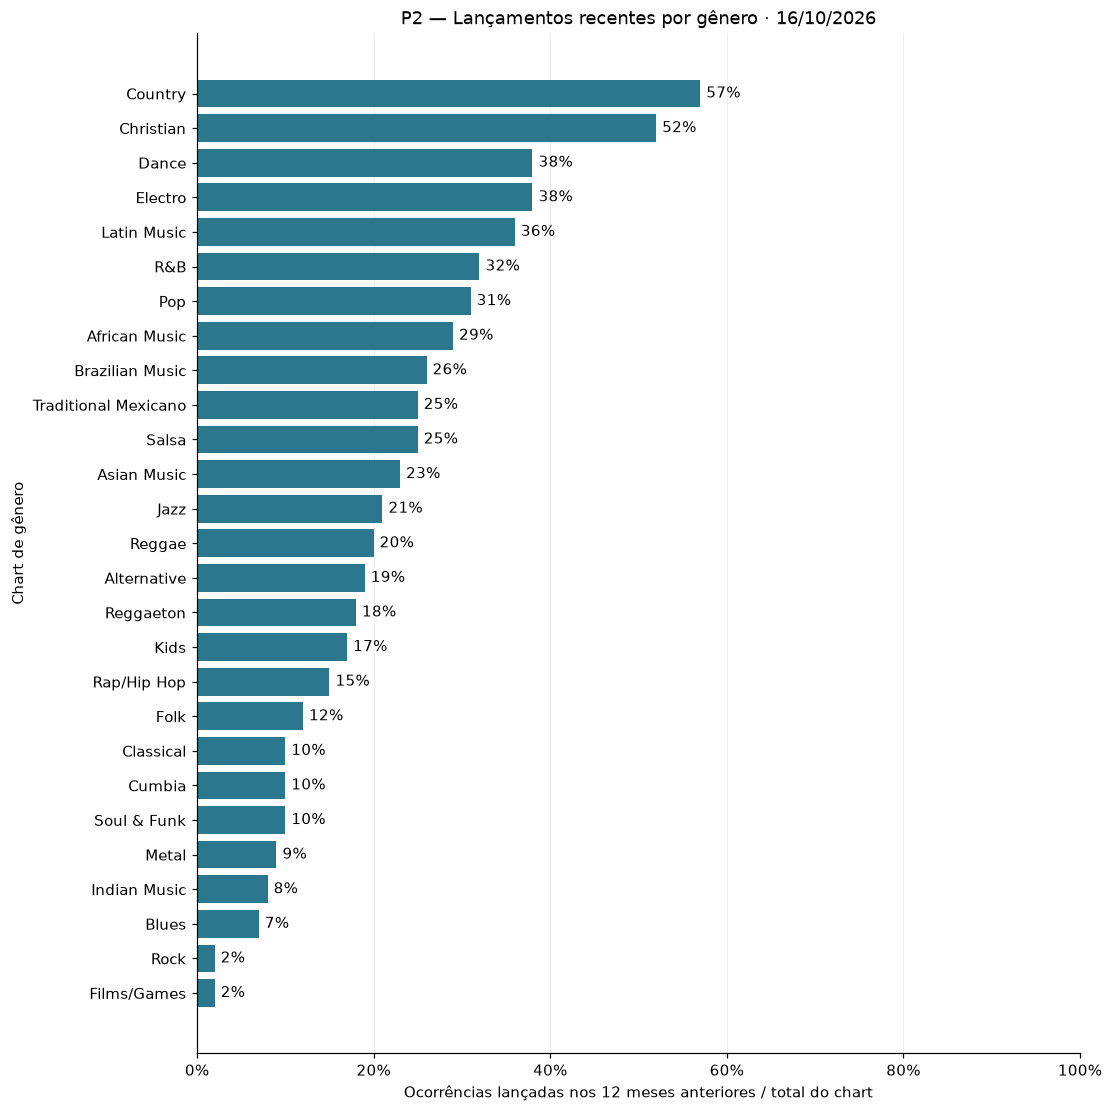

,recentes,ocorrencias,percentual
genero,,,
Films/Games,2,100,2.0
Rock,2,100,2.0
Blues,7,100,7.0
Indian Music,8,100,8.0
Metal,9,100,9.0
Soul & Funk,10,100,10.0
Cumbia,10,100,10.0
Classical,10,100,10.0
Folk,12,100,12.0


Janela inclusiva: 16/10/2025 a 16/10/2026.
Recentes: 592 de 2700 ocorrências. Lançamentos posteriores à coleta, fora do numerador: 1.


In [6]:
# Lançamentos nos 12 meses anteriores à coleta
inicio_janela_vis = df_generos_vis["data_coleta"] - pd.DateOffset(months=12)
df_generos_vis["recente_vis"] = (
    df_generos_vis["data_lancamento"].ge(inicio_janela_vis)
    & df_generos_vis["data_lancamento"].le(df_generos_vis["data_coleta"])
)
resumo_recentes_vis = (
    df_generos_vis.groupby("genero")["recente_vis"]
    .agg(recentes="sum", ocorrencias="size")
)
resumo_recentes_vis["percentual"] = (
    100 * resumo_recentes_vis["recentes"] / resumo_recentes_vis["ocorrencias"]
)
resumo_recentes_vis = resumo_recentes_vis.sort_values("percentual")
with plt.rc_context(estilo_vis):
    figura_vis, eixo_vis = plt.subplots(figsize=(10, 10), layout="constrained")
    barras_vis = eixo_vis.barh(resumo_recentes_vis.index, resumo_recentes_vis["percentual"], color="#2b788e")
    eixo_vis.bar_label(
        barras_vis,
        labels=[f"{valor:.0f}%" for valor in resumo_recentes_vis["percentual"]], padding=4,
    )
    eixo_vis.set_xlim(0, 100)
    eixo_vis.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    eixo_vis.set_xlabel("Ocorrências lançadas nos 12 meses anteriores / total do chart")
    eixo_vis.set_ylabel("Chart de gênero")
    eixo_vis.set_title(f"P2 — Lançamentos recentes por gênero · {data_retrato_vis}")
    eixo_vis.grid(axis="x", alpha=0.2)
    eixo_vis.set_axisbelow(True)
    plt.show()
display(resumo_recentes_vis)
print(f"Janela inclusiva: {inicio_janela_vis.min():%d/%m/%Y} a {df_generos_vis['data_coleta'].max():%d/%m/%Y}.")
print(f"Recentes: {df_generos_vis['recente_vis'].sum()} de {len(df_generos_vis)} ocorrências. "
      f"Lançamentos posteriores à coleta, fora do numerador: "
      f"{df_generos_vis['data_lancamento'].gt(df_generos_vis['data_coleta']).sum()}.")

**Interpretação — P2:** Country tem 57 lançamentos recentes em 100 ocorrências (57%), enquanto Rock e Films/Games têm 2 em 100 cada (2%). No conjunto dos gêneros, são 592 de 2.700 (21,9%). A janela inclui 16/10/2025 e 16/10/2026; o lançamento posterior à coleta fica fora do numerador, mantendo o total do chart como denominador. Isso descreve a renovação do topo dos charts nesse retrato. Fonte: seção 2, célula "Lançamentos nos 12 meses anteriores à coleta".

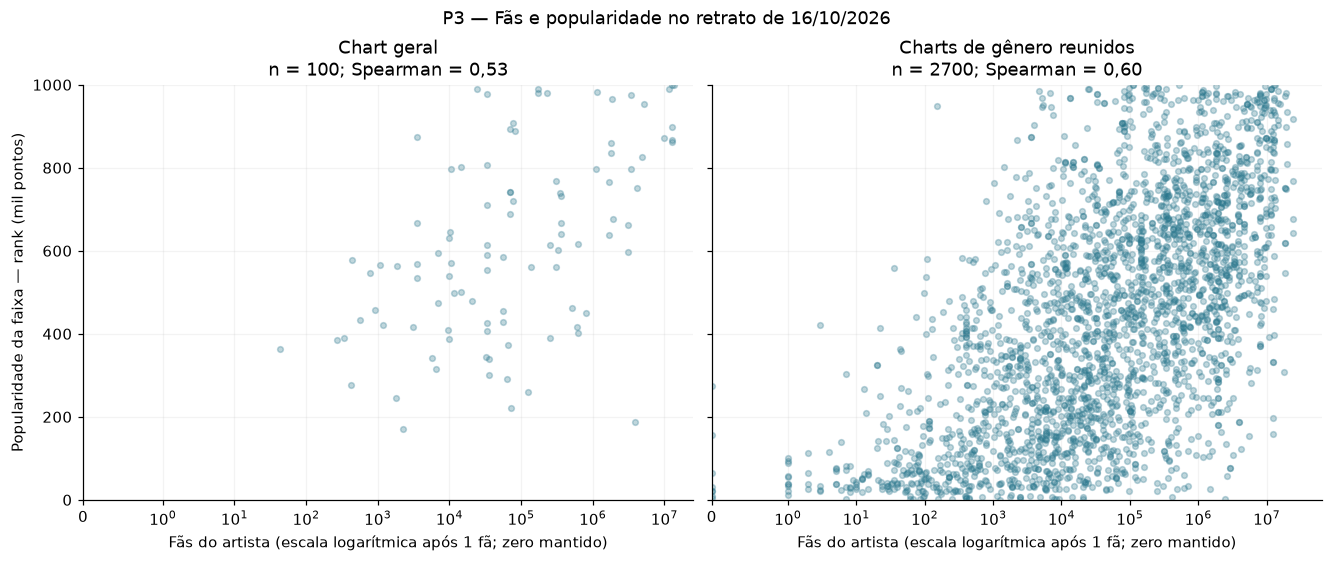

,recorte,ocorrencias,fas_iguais_zero,spearman
0,Chart geral,100,0,0.530
1,Charts de gênero reunidos,2700,8,0.601


In [7]:
# Fãs do artista e popularidade: chart geral e conjunto dos gêneros
# Spearman equivale à correlação de Pearson dos postos, com postos médios nos empates.
correlacoes_gerais_vis = []
with plt.rc_context(estilo_vis):
    figura_vis, eixos_vis = plt.subplots(1, 2, figsize=(12, 5), sharey=True, layout="constrained")
    for eixo_vis, (nome_vis, recorte_vis) in zip(
        eixos_vis, [("Chart geral", df_geral_vis), ("Charts de gênero reunidos", df_generos_vis)]
    ):
        correlacao_vis = recorte_vis["numero_fas"].rank().corr(recorte_vis["rank"].rank())
        correlacoes_gerais_vis.append({
            "recorte": nome_vis, "ocorrencias": len(recorte_vis),
            "fas_iguais_zero": int(recorte_vis["numero_fas"].eq(0).sum()),
            "spearman": correlacao_vis,
        })
        eixo_vis.scatter(recorte_vis["numero_fas"], recorte_vis["rank"], s=14, alpha=0.3, color="#2b788e")
        eixo_vis.set_xscale("symlog", linthresh=1)
        eixo_vis.set_xlim(left=0)
        eixo_vis.set_ylim(0, 1_000_000)
        eixo_vis.set_xlabel("Fãs do artista (escala logarítmica após 1 fã; zero mantido)")
        eixo_vis.set_title(f"{nome_vis}\nn = {len(recorte_vis)}; Spearman = {correlacao_vis:.2f}".replace(".", ","))
        eixo_vis.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor / 1000:.0f}"))
        eixo_vis.grid(alpha=0.15)
    eixos_vis[0].set_ylabel("Popularidade da faixa — rank (mil pontos)")
    figura_vis.suptitle(f"P3 — Fãs e popularidade no retrato de {data_retrato_vis}")
    plt.show()
display(pd.DataFrame(correlacoes_gerais_vis).round({"spearman": 3}))

**Interpretação — P3, visão geral:** a associação entre fãs e `rank` é positiva: Spearman de 0,53 nas 100 ocorrências do chart geral e 0,60 nas 2.700 dos charts de gênero reunidos. As 8 ocorrências de gênero com zero fãs continuam no gráfico e no cálculo. A dispersão mostra que o número de fãs não determina sozinho a popularidade de cada faixa. O resultado reunido mistura gêneros e não substitui a comparação dentro de cada um; também não demonstra causalidade. Fonte: seção 2, célula "Fãs do artista e popularidade: chart geral e conjunto dos gêneros".

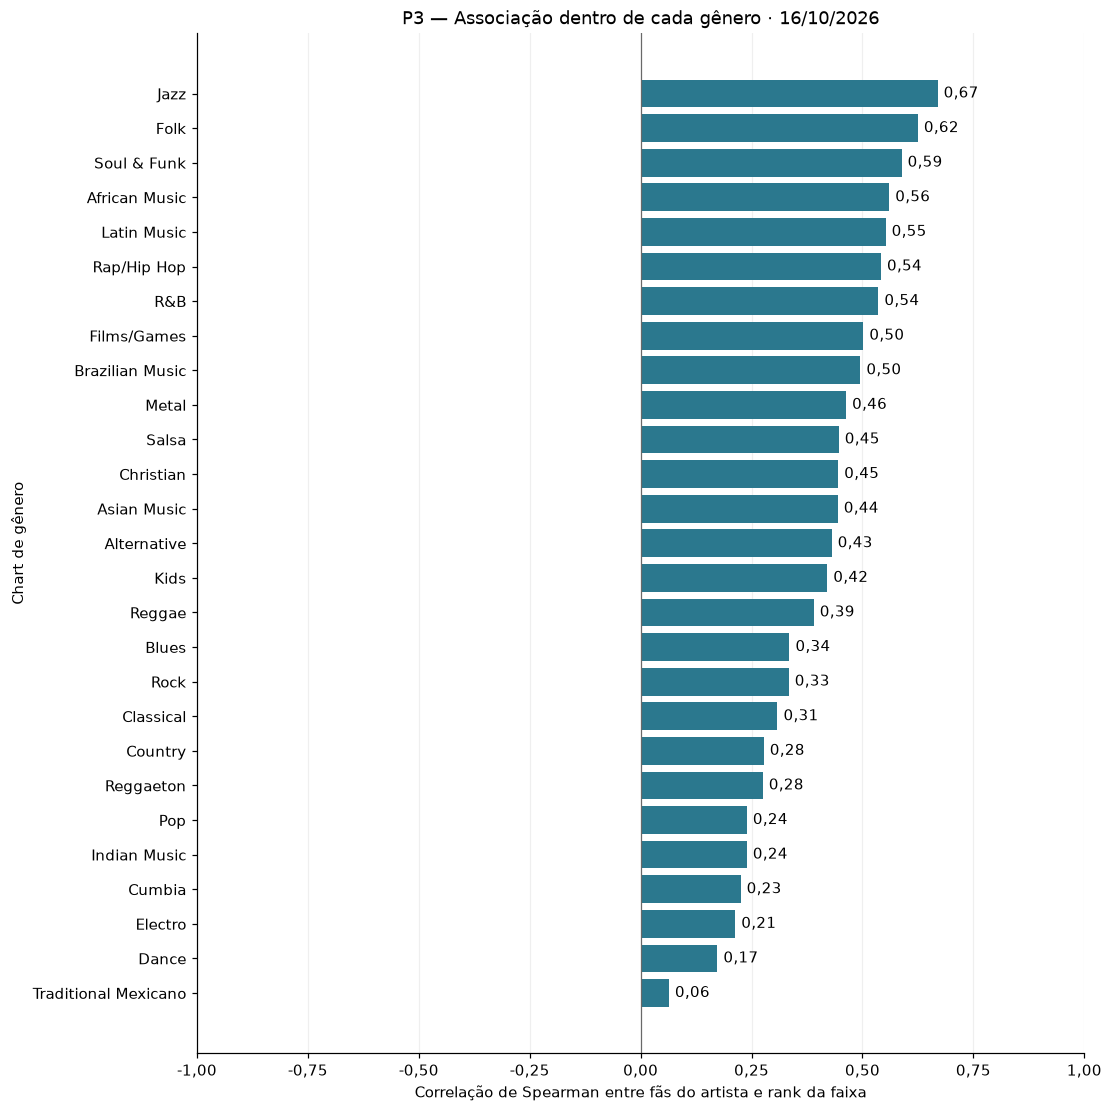

,ocorrencias,spearman
genero,,
Traditional Mexicano,100,0.064
Dance,100,0.173
Electro,100,0.213
Cumbia,100,0.225
Indian Music,100,0.239
Pop,100,0.239
Reggaeton,100,0.275
Country,100,0.277
Classical,100,0.308


In [8]:
# Associação entre fãs e popularidade dentro de cada gênero
correlacoes_genero_vis = pd.DataFrame([
    {"genero": genero_vis, "ocorrencias": len(grupo_vis),
     "spearman": grupo_vis["numero_fas"].rank().corr(grupo_vis["rank"].rank())}
    for genero_vis, grupo_vis in df_generos_vis.groupby("genero")
]).set_index("genero").sort_values("spearman")
with plt.rc_context(estilo_vis):
    figura_vis, eixo_vis = plt.subplots(figsize=(10, 10), layout="constrained")
    barras_vis = eixo_vis.barh(correlacoes_genero_vis.index, correlacoes_genero_vis["spearman"], color="#2b788e")
    eixo_vis.bar_label(
        barras_vis,
        labels=[f"{valor:.2f}".replace(".", ",") for valor in correlacoes_genero_vis["spearman"]], padding=4,
    )
    eixo_vis.set_xlim(-1, 1)
    eixo_vis.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:.2f}".replace(".", ",")))
    eixo_vis.axvline(0, color="dimgray", linewidth=0.8)
    eixo_vis.set_xlabel("Correlação de Spearman entre fãs do artista e rank da faixa")
    eixo_vis.set_ylabel("Chart de gênero")
    eixo_vis.set_title(f"P3 — Associação dentro de cada gênero · {data_retrato_vis}")
    eixo_vis.grid(axis="x", alpha=0.2)
    eixo_vis.set_axisbelow(True)
    plt.show()
display(correlacoes_genero_vis.round({"spearman": 3}))

**Interpretação — P3, por gênero:** a correlação é positiva nos 27 charts, mas varia de 0,06 em Traditional Mexicano a 0,67 em Jazz, com 100 ocorrências em cada um. Logo, a associação de 0,60 no conjunto reunido não descreve igualmente todos os gêneros. Esses coeficientes são descritivos das faixas observadas, sem teste de significância ou garantia de generalização. Fonte: seção 2, célula "Associação entre fãs e popularidade dentro de cada gênero".

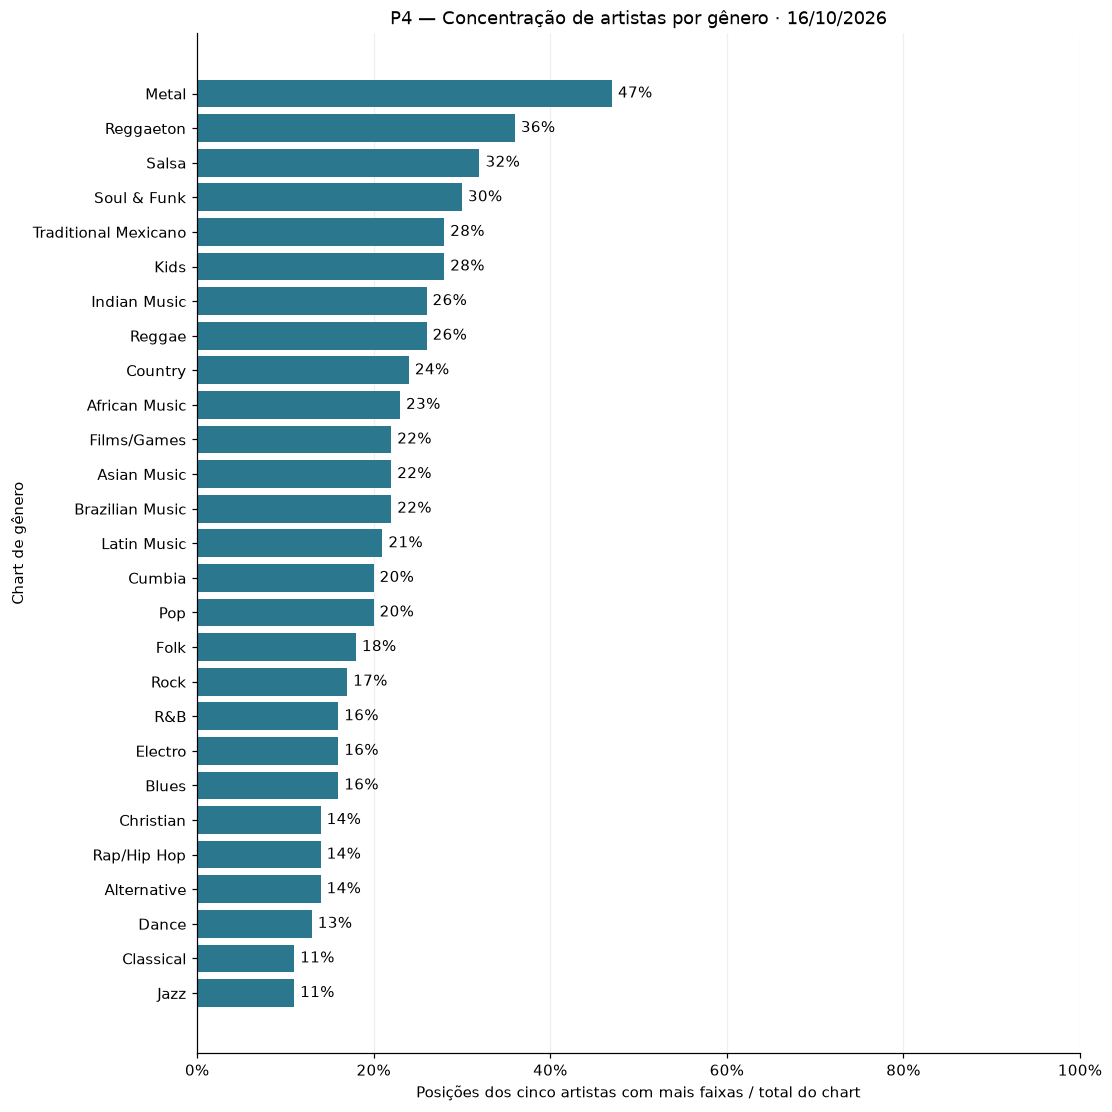

,id_chart,ocorrencias,artistas_distintos,posicoes_cinco_artistas,percentual
genero,,,,,
Jazz,129,100,93,11,11.0
Classical,98,100,94,11,11.0
Dance,113,100,85,13,13.0
Alternative,85,100,77,14,14.0
Rap/Hip Hop,116,100,82,14,14.0
Christian,186,100,83,14,14.0
Blues,153,100,77,16,16.0
Electro,106,100,83,16,16.0
R&B,165,100,77,16,16.0


In [9]:
# Concentração das posições nos cinco artistas mais presentes
contagem_artistas_vis = (
    df_generos_vis.groupby(["id_chart", "genero", "id_artista"])
    .size().rename("posicoes").reset_index()
)
# Desempate por identificador; o total das cinco maiores contagens não muda em empates.
cinco_artistas_vis = (
    contagem_artistas_vis.sort_values(["posicoes", "id_artista"], ascending=[False, True])
    .groupby(["id_chart", "genero"]).head(5)
)
resumo_concentracao_vis = df_generos_vis.groupby(["id_chart", "genero"]).agg(
    ocorrencias=("id_faixa", "size"), artistas_distintos=("id_artista", "nunique")
)
resumo_concentracao_vis["posicoes_cinco_artistas"] = (
    cinco_artistas_vis.groupby(["id_chart", "genero"])["posicoes"].sum()
)
resumo_concentracao_vis["percentual"] = (
    100 * resumo_concentracao_vis["posicoes_cinco_artistas"] / resumo_concentracao_vis["ocorrencias"]
)
resumo_concentracao_vis = resumo_concentracao_vis.reset_index().set_index("genero").sort_values("percentual")
with plt.rc_context(estilo_vis):
    figura_vis, eixo_vis = plt.subplots(figsize=(10, 10), layout="constrained")
    barras_vis = eixo_vis.barh(resumo_concentracao_vis.index, resumo_concentracao_vis["percentual"], color="#2b788e")
    eixo_vis.bar_label(
        barras_vis,
        labels=[f"{valor:.0f}%" for valor in resumo_concentracao_vis["percentual"]], padding=4,
    )
    eixo_vis.set_xlim(0, 100)
    eixo_vis.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    eixo_vis.set_xlabel("Posições dos cinco artistas com mais faixas / total do chart")
    eixo_vis.set_ylabel("Chart de gênero")
    eixo_vis.set_title(f"P4 — Concentração de artistas por gênero · {data_retrato_vis}")
    eixo_vis.grid(axis="x", alpha=0.2)
    eixo_vis.set_axisbelow(True)
    plt.show()
display(resumo_concentracao_vis)

**Interpretação — P4:** em Metal, os cinco artistas com mais faixas ocupam 47 das 100 posições (47%), e há 35 artistas distintos. Em Jazz e Classical, os cinco concentram 11 de 100 posições cada (11%), com 93 e 94 artistas distintos, respectivamente. Assim, charts com o mesmo tamanho podem ter concentração de artistas bastante diferente. A medida conta posições, não participação nas reproduções ou na audiência. Fonte: seção 2, célula "Concentração das posições nos cinco artistas mais presentes".

## 3. Amostragem e representatividade

Apresente uma breve análise sobre a representatividade dos dados utilizados, abordando:

- A origem e a abrangência do conjunto de dados.
- Se os registros representam adequadamente o problema investigado.
- Possíveis limitações ou vieses que possam influenciar os resultados.

Não é obrigatório implementar um procedimento de amostragem. Caso utilize uma amostra, explique como os registros foram selecionados.

In [10]:
# Utilize quantas células de código forem necessárias para esta etapa.

**Resposta do grupo:**

[Preencha aqui.]

## 4. Aplicação de Machine Learning

Implemente uma aplicação simples de aprendizagem supervisionada, por **classificação** (prever uma categoria ou classe) ou **regressão** (estimar um valor numérico). A implementação deverá contemplar:

1. Definição do problema preditivo.
2. Identificação da variável-alvo (*target*) e das características utilizadas (*features*).
3. Separação dos dados para treinamento e teste.
4. Treinamento de um modelo e realização de previsões.
5. Avaliação dos resultados utilizando pelo menos uma métrica adequada ao problema.

Caso o conjunto de dados original não possua características adequadas para uma aplicação supervisionada, outro conjunto de dados pode ser utilizado exclusivamente nesta etapa, com uma breve justificativa.

**Resposta do grupo:**

[Informe o problema preditivo, a variável-alvo e as características utilizadas.]

In [11]:
# Utilize quantas células de código forem necessárias para esta etapa.

**Resposta do grupo:**

[Explique brevemente a métrica obtida e interprete o desempenho do modelo.]

## 5. Conclusões do RA3

Apresente uma conclusão geral do RA3, contemplando:

- Principais resultados identificados nas análises estatísticas e nas visualizações.
- Interpretação do desempenho do modelo de Machine Learning.
- Limitações dos dados e das análises realizadas.
- Relação dos resultados com o problema definido no projeto.

**Resposta do grupo:**

[Preencha aqui.]